In [2]:
from pathlib import Path
print(Path.cwd().resolve())

/home/ibm-user/shared/PulsePalAI


In [4]:
!pip install -q huggingface_hub pandas tqdm joblib flask
import os, shutil, subprocess
import torch, numpy, pandas, huggingface_hub
print("torch", torch.__version__, "| numpy", numpy.__version__, "| pandas", pandas.__version__, "| hf_hub", huggingface_hub.__version__)
print("cpus:", os.cpu_count())
for t in ("gcc", "make", "curl", "tar"):
    print(f"{t:5} ->", shutil.which(t))
print(subprocess.run("df -h . | tail -1", shell=True, capture_output=True, text=True).stdout)


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
torch 2.11.0+cpu | numpy 2.0.2 | pandas 3.0.6 | hf_hub 1.33.0
cpus: 3
gcc   -> /usr/bin/gcc
make  -> /usr/bin/make
curl  -> /usr/bin/curl
tar   -> /usr/bin/tar
/dev/dasda1      50G   12G   36G  26% /home/ibm-user/shared



In [5]:
import subprocess
cmd = r'''
set -e
mkdir -p $HOME/shared/ffbuild && cd $HOME/shared/ffbuild
[ -f ff.tar.gz ] || curl -fL -o ff.tar.gz https://github.com/FFmpeg/FFmpeg/archive/refs/tags/n7.1.tar.gz
rm -rf FFmpeg-n7.1 && tar xzf ff.tar.gz && cd FFmpeg-n7.1
./configure --prefix=$HOME/shared/ffmpeg --disable-doc --disable-debug --disable-ffplay --disable-x86asm --disable-network
make -j$(nproc)
make install
echo BUILD_DONE
'''
subprocess.Popen(["bash", "-c", cmd], stdout=open("/home/ibm-user/shared/ffbuild.log", "w"),
                 stderr=subprocess.STDOUT, start_new_session=True)
print("build started - go on to Steps 3, 4 and 5 while it runs")

build started - go on to Steps 3, 4 and 5 while it runs


In [7]:
import subprocess
n = subprocess.run("ps aux | grep -E 'make|cc1|configure' | grep -v grep | wc -l", shell=True, capture_output=True, text=True).stdout.strip()
log = open("/home/ibm-user/shared/ffbuild.log").read()
print(n, "build processes |", len(log), "chars in log")
print(log[-300:])

0 build processes | 116996 chars in log
	libavutil/version.h
INSTALL	libavutil/video_enc_params.h
INSTALL	libavutil/xtea.h
INSTALL	libavutil/tea.h
INSTALL	libavutil/tx.h
INSTALL	libavutil/film_grain_params.h
INSTALL	libavutil/video_hint.h
INSTALL	libavutil/avconfig.h
INSTALL	libavutil/ffversion.h
INSTALL	libavutil/libavutil.pc
BUILD_DONE



In [9]:
import subprocess
sh = lambda c: print(subprocess.run(c, shell=True, capture_output=True, text=True).stdout)
sh("nproc; free -m")
sh("cd $HOME/shared/ffbuild/FFmpeg-n7.1 && find . -name '*.o' -size 0 -print -delete | head")   # remove empty half-written files
cmd = r'''
cd $HOME/shared/ffbuild/FFmpeg-n7.1 && make -j2 && make install && echo BUILD_DONE
'''
subprocess.Popen(["bash", "-c", cmd], stdout=open("/home/ibm-user/shared/ffbuild3.log", "w"),
                 stderr=subprocess.STDOUT, start_new_session=True)
print("resumed with 2 jobs")

3


resumed with 2 jobs


In [12]:
%%writefile pulsepal_core.py
import json, os, shutil, struct, subprocess, zlib
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn

FPS, WIN_S, STRIDE_S = 30, 10, 5
L = WIN_S * FPS
# face box (training side): centred square, side = BOX_SIDE x frame height
BOX_SIDE, BOX_CX, BOX_CY = 0.5, 0.5, 0.5
ROIS = [(0.25, 0.75, 0.05, 0.22), (0.12, 0.38, 0.50, 0.75),
        (0.62, 0.88, 0.50, 0.75), (0.20, 0.80, 0.20, 0.80)]   # forehead, L cheek, R cheek, centre (fractions of the box)

# ---------- signal helpers ----------
def read_table(path):
    df = pd.read_csv(path, sep=r"[,\s;]+", engine="python", header=None, comment="#")
    return df.apply(pd.to_numeric, errors="coerce").dropna(how="all").dropna(axis=1, how="all")

def load_ppg(path, col=None):
    df = read_table(path)
    col = df.columns[-1] if col is None else col
    return df[col].astype(float).interpolate().bfill().ffill().to_numpy()

def resample(x, n_out):
    x = np.asarray(x, float)
    if x.ndim == 1: x = x[:, None]
    a, b = np.linspace(0, 1, len(x)), np.linspace(0, 1, n_out)
    return np.stack([np.interp(b, a, x[:, i]) for i in range(x.shape[1])], 1)

def bandpass(x, fs, lo, hi):
    x = np.asarray(x, float)
    F = np.fft.rfft(x - x.mean(axis=0), axis=0)
    f = np.fft.rfftfreq(x.shape[0], 1.0 / fs)
    F[(f < lo) | (f > hi)] = 0
    return np.fft.irfft(F, n=x.shape[0], axis=0)

def hr_snr(x, fs=FPS, lo=0.7, hi=3.0, nfft=8192):
    """-> (heart rate bpm, spectral SNR dB) of a pulse waveform"""
    x = np.asarray(x, float); x = (x - x.mean()) * np.hanning(len(x))
    P = np.abs(np.fft.rfft(x, n=nfft)) ** 2; f = np.fft.rfftfreq(nfft, 1.0 / fs)
    band = (f >= lo) & (f <= hi); pk = f[band][np.argmax(P[band])]
    s = P[band & (np.abs(f - pk) <= 0.1)].sum(); n = P[band].sum() - s
    return 60.0 * pk, 10 * np.log10((s + 1e-12) / (n + 1e-12))

def pos_signal(rgb, fs, win_s=1.6):          # classic POS baseline, no training
    T, w = len(rgb), int(win_s * fs); H = np.zeros(T)
    for t in range(T - w + 1):
        C = rgb[t:t + w].T
        Cn = C / (C.mean(axis=1, keepdims=True) + 1e-9)
        S1 = Cn[1] - Cn[2]; S2 = -2 * Cn[0] + Cn[1] + Cn[2]
        h = S1 + (S1.std() / (S2.std() + 1e-9)) * S2
        H[t:t + w] += h - h.mean()
    return H

def align(sig, ppg, fs=FPS, max_lag=20):
    """shift/sign-fix the PPG label so it lines up with the face signal (+-20 frames)"""
    pos = bandpass(pos_signal(sig.reshape(-1, 4, 3).mean(1), fs), fs, 0.7, 3.0)
    p = bandpass(ppg, fs, 0.7, 3.0); best, bl = 0.0, 0
    for lag in range(-max_lag, max_lag + 1):
        a, b = (pos[lag:], p[:len(p) - lag]) if lag >= 0 else (pos[:lag], p[-lag:])
        n = min(len(a), len(b)); c = np.corrcoef(a[:n], b[:n])[0, 1]
        if np.isfinite(c) and abs(c) > abs(best): best, bl = c, lag
    s2, p2 = (sig[bl:], ppg[:len(ppg) - bl]) if bl >= 0 else (sig[:bl], ppg[-bl:])
    n = min(len(s2), len(p2))
    return s2[:n], (p2[:n] if best >= 0 else -p2[:n]), bl, best

# ---------- video reading through ffmpeg (no OpenCV) ----------
def _ff(name):
    d = Path(os.environ.get("PULSEPAL_FFMPEG", Path(__file__).resolve().parent.parent / "ffmpeg" / "bin"))
    p = d / name
    return str(p) if p.exists() else (shutil.which(name) or str(p))

def video_info(path):
    r = subprocess.run([_ff("ffprobe"), "-v", "error", "-select_streams", "v:0", "-of", "json",
                        "-show_entries", "stream=codec_name,width,height,avg_frame_rate,r_frame_rate",
                        str(path)], capture_output=True, text=True)
    if r.returncode != 0 or not r.stdout.strip():
        raise RuntimeError(f"ffprobe failed: {r.stderr.strip()[:200]}")
    s = json.loads(r.stdout)["streams"][0]
    def rate(t):
        a, b = (t.split("/") + ["1"])[:2]
        return float(a) / float(b) if float(b) else 0.0
    fps = rate(s.get("avg_frame_rate", "0/1")) or rate(s.get("r_frame_rate", "0/1")) or 30.0
    return dict(codec=s.get("codec_name"), width=int(s["width"]), height=int(s["height"]), fps=fps)

def iter_frames(path, out_w=480, max_s=None):
    """-> (generator of RGB uint8 frames (H,W,3) scaled to out_w wide, fps)"""
    info = video_info(path)
    W = out_w - out_w % 2; H = int(round(info["height"] * W / info["width"] / 2)) * 2
    cmd = [_ff("ffmpeg"), "-v", "error", "-nostdin"]
    if max_s: cmd += ["-t", str(max_s)]
    cmd += ["-i", str(path), "-an", "-sn", "-vf", f"scale={W}:{H}", "-fps_mode", "passthrough",
            "-f", "rawvideo", "-pix_fmt", "rgb24", "-"]
    def gen():
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL); n = W * H * 3
        try:
            while True:
                buf = p.stdout.read(n)
                if len(buf) < n: break
                yield np.frombuffer(buf, np.uint8).reshape(H, W, 3)
        finally:
            p.stdout.close()
            try: p.kill()
            except Exception: pass
            p.wait()
    return gen(), info["fps"]

# ---------- video -> 12 colour signals (training side only) ----------
def box_for(H, W):
    s = BOX_SIDE * H
    return W * BOX_CX - s / 2, H * BOX_CY - s / 2, s, s

def extract_signals(video_path, max_s=None):
    frames, fps = iter_frames(video_path, max_s=max_s); feats = []
    for fr in frames:
        H, W = fr.shape[:2]; x, y, w, h = box_for(H, W); row = []
        for x0, x1, y0, y1 in ROIS:
            ya, yb = int(y + y0 * h), max(int(y + y1 * h), int(y + y0 * h) + 1)
            xa, xb = int(x + x0 * w), max(int(x + x1 * w), int(x + x0 * w) + 1)
            row.extend(fr[ya:yb, xa:xb].reshape(-1, 3).mean(0))         # R, G, B per region
        feats.append(row)
    return np.array(feats, float), fps

def overlay(frame):
    """draw the face box (green) and the 4 regions (yellow) on a frame, to check the placement"""
    out = np.array(frame, np.uint8, copy=True); H, W = out.shape[:2]; x, y, w, h = box_for(H, W)
    def rect(xa, ya, xb, yb, col, t):
        xa, xb = int(max(0, xa)), int(min(W, xb)); ya, yb = int(max(0, ya)), int(min(H, yb))
        out[ya:ya + t, xa:xb] = col; out[yb - t:yb, xa:xb] = col
        out[ya:yb, xa:xa + t] = col; out[ya:yb, xb - t:xb] = col
    rect(x, y, x + w, y + h, (0, 255, 0), 2)
    for x0, x1, y0, y1 in ROIS: rect(x + x0 * w, y + y0 * h, x + x1 * w, y + y1 * h, (255, 255, 0), 1)
    return out

def save_png(arr, path):
    a = np.ascontiguousarray(arr, np.uint8); H, W = a.shape[:2]
    raw = b"".join(b"\x00" + a[i].tobytes() for i in range(H))
    def chunk(t, d):
        c = struct.pack(">I", len(d)) + t + d
        return c + struct.pack(">I", zlib.crc32(t + d) & 0xffffffff)
    with open(path, "wb") as f:
        f.write(b"\x89PNG\r\n\x1a\n" + chunk(b"IHDR", struct.pack(">IIBBBBB", W, H, 8, 2, 0, 0, 0))
                + chunk(b"IDAT", zlib.compress(raw)) + chunk(b"IEND", b""))

# ---------- model ----------
def preprocess(sig):                 # sig (T,12) at 30 fps -> filtered, scale-free
    return bandpass(sig / (sig.mean(0) + 1e-9) - 1.0, FPS, 0.6, 3.5)

def make_windows(x, stride=STRIDE_S * FPS):
    W = [((x[s:s + L] - x[s:s + L].mean(0)) / (x[s:s + L].std(0) + 1e-8)).T.astype(np.float32)
         for s in range(0, len(x) - L + 1, stride)]
    return np.stack(W) if W else np.zeros((0, x.shape[1], L), np.float32)

class PulseNet(nn.Module):
    def __init__(self, in_ch=12, hid=64):
        super().__init__()
        def blk(i, o, d): return nn.Sequential(nn.Conv1d(i, o, 7, padding=3 * d, dilation=d), nn.BatchNorm1d(o), nn.GELU())
        self.net = nn.Sequential(blk(in_ch, hid, 1), blk(hid, hid, 2), blk(hid, hid, 4),
                                 blk(hid, hid, 8), blk(hid, hid, 1), nn.Conv1d(hid, 1, 1))
    def forward(self, x): return self.net(x).squeeze(1)

def pearson_loss(p, y):
    p = p - p.mean(1, keepdim=True); y = y - y.mean(1, keepdim=True)
    return (1 - (p * y).sum(1) / (p.norm(dim=1) * y.norm(dim=1) + 1e-8)).mean()

@torch.no_grad()
def predict(model, X, bs=128):
    model.eval(); out = [model(torch.as_tensor(X[i:i + bs])).cpu() for i in range(0, len(X), bs)]
    return torch.cat(out).numpy() if out else np.zeros((0, L))

def estimate_hr(model, sig30):
    """what the app calls: 12 colour signals at 30 fps -> HR + quality"""
    X = make_windows(preprocess(np.asarray(sig30, float)), stride=2 * FPS)
    if len(X) == 0: return None
    r = np.array([hr_snr(w) for w in predict(model, X)]); hrs, snr = r[:, 0], r[:, 1]
    good = snr > -3 if (snr > -3).any() else np.ones(len(snr), bool)
    return dict(hr=float(np.median(hrs[good])), snr_db=float(np.median(snr)),
                spread=float(np.std(hrs[good])), n_windows=int(len(X)))

# ---------- risk flag: partial NEWS2 (RCP) + ESI danger zones; screening aid, not diagnosis ----------
def s_hr(x):   return 3 if x <= 40 else 1 if x <= 50 else 0 if x <= 90 else 1 if x <= 110 else 2 if x <= 130 else 3
def s_rr(x):   return 3 if x <= 8 else 1 if x <= 11 else 0 if x <= 20 else 2 if x <= 24 else 3
def s_spo2(x): return 3 if x <= 91 else 2 if x <= 93 else 1 if x <= 95 else 0
def s_sbp(x):  return 3 if x <= 90 else 2 if x <= 100 else 1 if x <= 110 else 0 if x <= 219 else 3
def s_temp(x): return 3 if x <= 35.0 else 1 if x <= 36.0 else 0 if x <= 38.0 else 1 if x <= 39.0 else 2

def assess(hr=None, rr=None, spo2=None, sbp=None, temp=None, age=None):
    if age is not None and age < 18:
        return dict(light="NOT VALIDATED", total=None, worst=None, items={}, flags=[], note="Adult thresholds only (age 18+).")
    spec = dict(HR=(hr, s_hr), RR=(rr, s_rr), SpO2=(None if spo2 is None else round(spo2), s_spo2),
                SBP=(sbp, s_sbp), Temp=(temp, s_temp))
    items = {k: (float(v), int(f(v))) for k, (v, f) in spec.items() if v is not None}
    total = sum(s for _, s in items.values()); worst = max([s for _, s in items.values()] or [0])
    flags = []
    if hr is not None and hr > 100: flags.append("HR above 100 (ESI danger zone)")
    if rr is not None and rr > 20: flags.append("RR above 20 (ESI danger zone)")
    if spo2 is not None and spo2 < 92: flags.append("SpO2 below 92% (ESI danger zone)")
    light = "RED" if (worst == 3 or total >= 5) else "YELLOW" if (total >= 1 or flags) else "GREEN"
    return dict(light=light, total=int(total), worst=int(worst), items=items, flags=flags, note="")

Overwriting pulsepal_core.py


In [13]:
import importlib, pulsepal_core
importlib.reload(pulsepal_core)
print(pulsepal_core.assess(hr=75, rr=16, spo2=97, sbp=120, temp=36.8, age=30)["light"])   # expect GREEN

GREEN


In [1]:
from pathlib import Path
import os, getpass, numpy as np, pandas as pd
from collections import Counter
from pulsepal_core import *

BASE = Path.cwd(); RAW = BASE/"data"/"mcd_rppg"; SIG = BASE/"data"/"signals"; MODELS = BASE/"models"
for p in (RAW, SIG, MODELS): p.mkdir(parents=True, exist_ok=True)

REPO = "kyegorov/mcd_rppg"
BUDGET_GB, MAX_PATIENTS, SEED = 5, 200, 42
PPG_COL = 0               # ppg_sync column 0 = PPG waveform (verified from the real file)
N_JOBS = 2                # parallel video workers; check os.cpu_count()
MAX_SECONDS = 60          # use the first 60 s of each video (enough windows, much faster)

if not os.environ.get("HF_TOKEN"):
    t = getpass.getpass("NEW HF token (Enter to skip): ")
    if t: os.environ["HF_TOKEN"] = t

if (RAW/"db.csv").exists() and (BASE/"data"/"subset.csv").exists():      # reload after a kernel restart
    db = pd.read_csv(RAW/"db.csv"); sub = pd.read_csv(BASE/"data"/"subset.csv"); print("reloaded db and sub:", len(sub), "videos")

NEW HF token (Enter to skip):  ········


In [3]:
DOWNLOAD = True          # <- change to True for the real download, then run this cell again

from huggingface_hub import HfApi, hf_hub_download, snapshot_download
api = HfApi()
db = pd.read_csv(hf_hub_download(REPO, "db.csv", repo_type="dataset", local_dir=RAW))
front = db[db.camera == "FullHDwebcam"].copy()

size = {}
for folder in ("video", "ppg_sync"):
    for f in api.list_repo_tree(REPO, path_in_repo=folder, repo_type="dataset"):
        size[f.path] = getattr(f, "size", 0) or 0
front["bytes"] = [size.get(r.video, 0) + size.get(r.ppg_sync, 0) for r in front.itertuples()]
assert front.bytes.sum() > 0, "Could not read file sizes - stop, do not download."
print(f"ALL front recordings: {front.bytes.sum()/1e9:.1f} GB | avg {front.bytes.mean()/1e6:.1f} MB each")

rng = np.random.default_rng(SEED)
rare = front[(front.age >= 40) | (front.saturation <= 95) | (front.respiratory >= 22)].patient_id.unique().tolist()
rest = [p for p in front.patient_id.unique().tolist() if p not in set(rare)]; rng.shuffle(rest)
chosen, total = [], 0
for pid in rare + rest:
    rows = front[front.patient_id == pid]
    if len(rows) == 2 and total + rows.bytes.sum() <= BUDGET_GB * 1e9 and len(chosen) < MAX_PATIENTS:
        chosen.append(pid); total += rows.bytes.sum()
sub = front[front.patient_id.isin(chosen)].reset_index(drop=True)
print(f"SUBSET: {len(chosen)} patients, {len(sub)} videos, {total/1e9:.2f} GB")

if DOWNLOAD:
    snapshot_download(REPO, repo_type="dataset", local_dir=RAW, max_workers=8,
                      allow_patterns=["db.csv"] + sub.video.tolist() + sub.ppg_sync.tolist())
    print("download finished")
sub.to_csv(BASE/"data"/"subset.csv", index=False)

ALL front recordings: 58.3 GB | avg 48.5 MB each
SUBSET: 45 patients, 90 videos, 5.00 GB


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 181 files:   0%|          | 0/181 [00:00<?, ?it/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not in

download finished


In [4]:
print(len(list((RAW/"video").glob("*.avi"))), "videos |", len(list((RAW/"ppg_sync").glob("*.txt"))), "ppg_sync files")
!du -sh data/mcd_rppg

90 videos | 90 ppg_sync files
4.7G	data/mcd_rppg


ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
video exists: True | MB: 22.0
ffprobe: {'codec': 'mpeg4', 'width': 640, 'height': 480, 'fps': 29.9}
decoded 5371 frames in 11 s | fps 29.90 | ppg rows 5371 | frame shape (360, 480, 3)
ppg_sync columns: [0, 1] | head: 136 0.030916 | 140 0.0 | 144 0.000983 | 134 0.000978 | 130 0.00097 | 135 0.000966 | 143 0.00
labels: age 19.0 SpO2 98.0 RR 22.0 pulse 105.0 state after


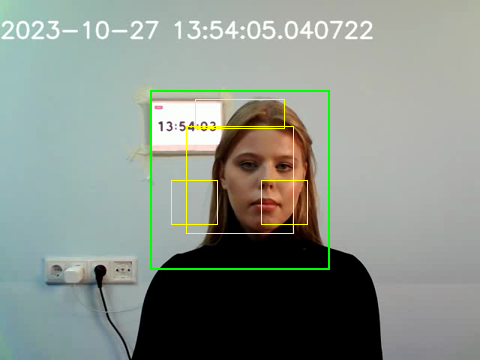

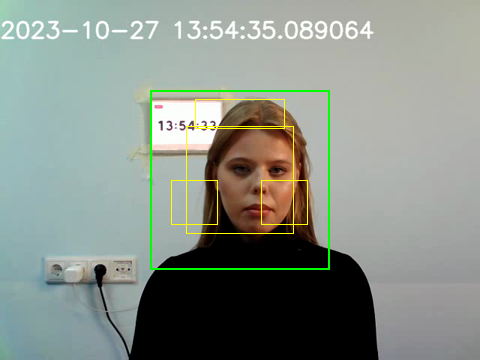

In [5]:
import subprocess, time
from IPython.display import Image, display
import importlib, pulsepal_core; importlib.reload(pulsepal_core)
from pulsepal_core import *

print(subprocess.run([pulsepal_core._ff("ffmpeg"), "-version"], capture_output=True, text=True).stdout.splitlines()[0])

r = sub.iloc[0]; p = RAW / r.video
print("video exists:", p.exists(), "| MB:", round(p.stat().st_size / 1e6, 1))
print("ffprobe:", video_info(p))

t0 = time.time(); n = 0; keep = {}
frames, fps = iter_frames(p)
for f in frames:
    if n in (0, 900): keep[n] = overlay(f)
    n += 1
tab = read_table(RAW / r.ppg_sync)
print(f"decoded {n} frames in {time.time()-t0:.0f} s | fps {fps:.2f} | ppg rows {len(tab)} | frame shape {f.shape}")
print("ppg_sync columns:", list(tab.columns), "| head:", open(RAW / r.ppg_sync).read()[:80].replace("\n", " | "))
print("labels: age", r.age, "SpO2", r.saturation, "RR", r.respiratory, "pulse", r.pulse, "state", r.step)
for k, im in keep.items():
    save_png(im, f"box_check_{k}.png"); display(Image(filename=f"box_check_{k}.png"))

In [6]:
PILOT = 10                # None = process everything

from joblib import Parallel, delayed
from tqdm.auto import tqdm

def process_one(r):
    out = SIG / f"{r.patient_id}_{r.step}.npz"
    if out.exists(): return "cached"
    try:
        sig, fps = extract_signals(RAW / r.video, max_s=MAX_SECONDS)
        if len(sig) < 20 * FPS: return "too_short"
        ppg = load_ppg(RAW / r.ppg_sync, PPG_COL)[:len(sig)]          # about 1 ppg row per video frame
        if len(ppg) < 0.9 * len(sig): return "ppg_short"
        n30 = int(round(len(sig) * FPS / fps))
        s30, p30 = resample(sig, n30), resample(ppg, n30)[:, 0]
        s30, p30, lag, corr = align(s30, p30)
        if abs(corr) < 0.15: return "bad_sync"
        np.savez_compressed(out, sig=s30.astype(np.float32), ppg=p30.astype(np.float32), lag=lag, corr=corr)
        return "ok"
    except Exception as e:
        return f"error: {type(e).__name__}: {str(e)[:80]}"

rows = list(sub.itertuples()); rows = rows[:PILOT] if PILOT else rows
res = Parallel(n_jobs=N_JOBS, prefer="threads")(delayed(process_one)(r) for r in tqdm(rows))
print(Counter(res))
info = [np.load(f) for f in sorted(SIG.glob("*.npz"))]
if info:
    print("lag frames (5/50/95%):", np.percentile([int(i["lag"]) for i in info], [5, 50, 95]),
          "| |corr| (5/50/95%):", np.percentile([abs(float(i["corr"])) for i in info], [5, 50, 95]).round(2))

  0%|          | 0/10 [00:00<?, ?it/s]

Counter({'ok': 8, 'bad_sync': 2})
lag frames (5/50/95%): [-14.45   2.    15.1 ] | |corr| (5/50/95%): [0.18 0.38 0.66]


In [7]:
import torch
torch.set_num_threads(os.cpu_count()); torch.manual_seed(SEED)
X, Y, HR, HRP, PID, STEP = [], [], [], [], [], []
for fp in sorted(SIG.glob("*.npz")):
    pid, step = fp.stem.split("_"); d = np.load(fp)
    sg = d["sig"].astype(float); x = preprocess(sg); y = bandpass(d["ppg"].astype(float), FPS, 0.6, 3.5)
    pos = bandpass(pos_signal(sg.reshape(-1, 4, 3).mean(1), FPS), FPS, 0.6, 3.5)
    for s in range(0, len(x) - L + 1, STRIDE_S * FPS):
        xw, yw = x[s:s+L], y[s:s+L]
        X.append(((xw - xw.mean(0)) / (xw.std(0) + 1e-8)).T.astype(np.float32))
        Y.append(((yw - yw.mean()) / (yw.std() + 1e-8)).astype(np.float32))
        HR.append(hr_snr(yw)[0]); HRP.append(hr_snr(pos[s:s+L])[0]); PID.append(int(pid)); STEP.append(step)
X, Y, HR, HRP, PID, STEP = map(np.array, (X, Y, HR, HRP, PID, STEP))

pids = np.array(sorted(set(PID.tolist()))); np.random.default_rng(SEED).shuffle(pids); n = len(pids)
sets = [set(pids[a:b].tolist()) for a, b in ((0, int(.7*n)), (int(.7*n), int(.85*n)), (int(.85*n), n))]
mtr, mva, mte = [np.array([p in S for p in PID]) for S in sets]
print(f"{n} patients | windows train {mtr.sum()} / val {mva.sum()} / test {mte.sum()}")

Xtr, Ytr = torch.tensor(X[mtr]), torch.tensor(Y[mtr])
model = PulseNet(); opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=1e-4)
best, state = 1e9, None
for ep in range(15):
    model.train(); perm = torch.randperm(len(Xtr)); tl = 0.0
    for i in range(0, len(perm), 64):
        b = perm[i:i+64]; xb = Xtr[b] + 0.05 * torch.randn_like(Xtr[b])
        loss = pearson_loss(model(xb), Ytr[b]); opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(b)
    mae = np.abs(np.array([hr_snr(w)[0] for w in predict(model, X[mva])]) - HR[mva]).mean()
    print(f"epoch {ep+1:02d} | train loss {tl/len(Xtr):.3f} | val HR MAE {mae:.2f} bpm")
    if mae < best: best, state = mae, {k: v.clone() for k, v in model.state_dict().items()}
model.load_state_dict(state)
torch.save({"state": model.state_dict(), "in_ch": 12, "hid": 64}, MODELS / "pulsenet.pt")
print("saved best model, val MAE", round(best, 2))

5 patients | windows train 50 / val 20 / test 10
epoch 01 | train loss 1.003 | val HR MAE 7.08 bpm
epoch 02 | train loss 0.537 | val HR MAE 11.24 bpm
epoch 03 | train loss 0.400 | val HR MAE 11.11 bpm
epoch 04 | train loss 0.323 | val HR MAE 12.66 bpm
epoch 05 | train loss 0.270 | val HR MAE 10.60 bpm
epoch 06 | train loss 0.233 | val HR MAE 10.58 bpm
epoch 07 | train loss 0.201 | val HR MAE 9.92 bpm
epoch 08 | train loss 0.172 | val HR MAE 9.28 bpm
epoch 09 | train loss 0.148 | val HR MAE 8.87 bpm
epoch 10 | train loss 0.128 | val HR MAE 9.16 bpm
epoch 11 | train loss 0.113 | val HR MAE 9.18 bpm
epoch 12 | train loss 0.100 | val HR MAE 9.24 bpm
epoch 13 | train loss 0.088 | val HR MAE 9.26 bpm
epoch 14 | train loss 0.078 | val HR MAE 8.80 bpm
epoch 15 | train loss 0.069 | val HR MAE 8.82 bpm
saved best model, val MAE 7.08


In [8]:
W = predict(model, X[mte]); r_ = np.array([hr_snr(w) for w in W]); hr_m, snr_m = r_[:, 0], r_[:, 1]
def mt(ref, est):
    e = est - ref
    return {k: round(float(v), 2) for k, v in dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e**2).mean()),
            r=np.corrcoef(ref, est)[0, 1], within5=100*(np.abs(e) <= 5).mean()).items()}
print("POS  :", mt(HR[mte], HRP[mte])); print("Model:", mt(HR[mte], hr_m))
for s in ("before", "after"):
    k = STEP[mte] == s; print(f"{s:<6} n={k.sum():<5} POS MAE {mt(HR[mte][k], HRP[mte][k])['MAE']} | model MAE {mt(HR[mte][k], hr_m[k])['MAE']}")
for thr in (-6, -3, 0, 3):
    k = snr_m >= thr
    if k.sum() > 10: print(f"SNR >= {thr:>2} dB: keeps {100*k.mean():.0f}% of windows, MAE {np.abs(hr_m[k]-HR[mte][k]).mean():.2f}")

lab = db.drop_duplicates(["patient_id", "step"]).set_index(["patient_id", "step"])
d = pd.DataFrame(dict(pid=PID[mte], step=STEP[mte], ref=HR[mte], model=hr_m)).groupby(["pid", "step"]).median().reset_index()
pairs = []
for r in d.itertuples():
    q = lab.loc[(r.pid, r.step)]
    kw = dict(rr=q.respiratory, spo2=q.saturation, sbp=q.upper_ap, temp=q.temperature, age=q.age)
    pairs.append((assess(hr=r.ref, **kw)["light"], assess(hr=r.model, **kw)["light"]))
pr = pd.DataFrame(pairs, columns=["reference_HR", "model_HR"])
print(f"traffic-light agreement: {(pr.reference_HR == pr.model_HR).mean()*100:.1f}% of {len(pr)} recordings")
print(pd.crosstab(pr.reference_HR, pr.model_HR))

POS  : {'MAE': 27.64, 'RMSE': 31.42, 'r': 0.1, 'within5': 10.0}
Model: {'MAE': 16.74, 'RMSE': 21.15, 'r': -0.02, 'within5': 20.0}
before n=0     POS MAE nan | model MAE nan
after  n=10    POS MAE 27.64 | model MAE 16.74
traffic-light agreement: 100.0% of 1 recordings
model_HR      YELLOW
reference_HR        
YELLOW             1


/tmp/ipykernel_10044/835881488.py:4: RuntimeWarning: Mean of empty slice.
  return {k: round(float(v), 2) for k, v in dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e**2).mean()),
/opt/venv/lib64/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/venv/lib64/python3.12/site-packages/numpy/lib/_function_base_impl.py:557: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/opt/venv/lib64/python3.12/site-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/opt/venv/lib64/python3.12/site-packages/numpy/lib/_function_base_impl.py:2914: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/opt/venv/lib64/python3.12/site-packages/numpy/lib/_function_base_impl.py:2773: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/opt/venv/lib64/python3.12/site

In [9]:
f = sorted(SIG.glob("*.npz"))[0]; d = np.load(f)
est = estimate_hr(model, d["sig"].astype(float))
ref = np.median([hr_snr(d["ppg"][s:s+L].astype(float))[0] for s in range(0, len(d["ppg"]) - L, 150)])
print(f.name, est, "| reference HR:", round(ref, 1))

1097_after.npz {'hr': 79.1015625, 'snr_db': -0.4995499446786686, 'spread': 11.327075842555049, 'n_windows': 25} | reference HR: 91.1


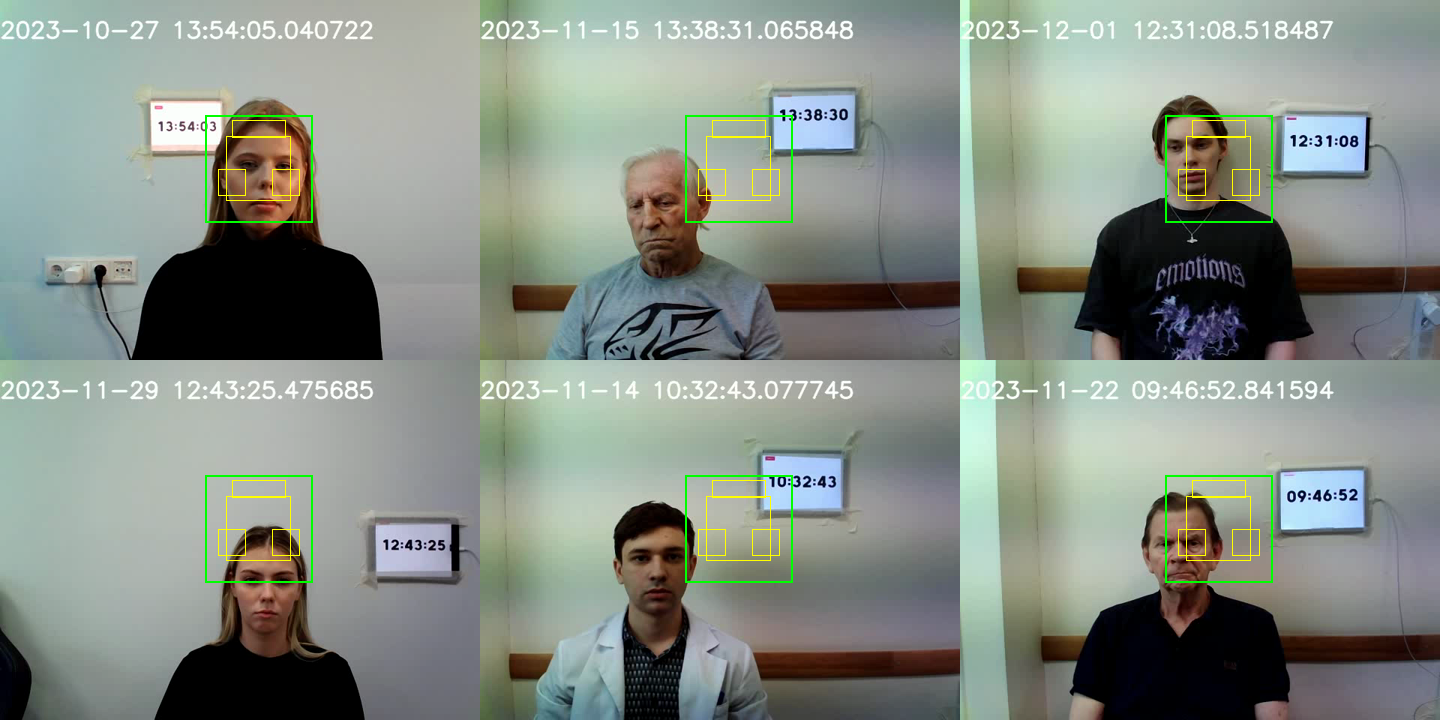

In [10]:
import re, importlib, pulsepal_core
src = open("pulsepal_core.py").read()
src = re.sub(r"BOX_SIDE, BOX_CX, BOX_CY = [^\n]+", "BOX_SIDE, BOX_CX, BOX_CY = 0.30, 0.54, 0.47", src)
open("pulsepal_core.py", "w").write(src)
importlib.reload(pulsepal_core)
from pulsepal_core import *

tiles = []
for pid in sub.patient_id.unique()[:6]:
    r = sub[sub.patient_id == pid].iloc[0]
    frames, _ = iter_frames(RAW / r.video)
    tiles.append(overlay(next(frames))); frames.close()
grid = np.concatenate([np.concatenate(tiles[:3], 1), np.concatenate(tiles[3:6], 1)], 0)
save_png(grid, "box_check_grid.png")
from IPython.display import Image, display; display(Image(filename="box_check_grid.png"))

In [11]:
import subprocess, sys
cmd = f'CMAKE_ARGS="-DBUILD_opencv_dnn=OFF" CMAKE_BUILD_PARALLEL_LEVEL=2 {sys.executable} -m pip install --no-cache-dir opencv-python-headless==4.10.0.84'
subprocess.Popen(["bash", "-c", cmd + " && echo CV_DONE"], stdout=open("/home/ibm-user/shared/cvbuild.log", "w"),
                 stderr=subprocess.STDOUT, start_new_session=True)
print("started")

started


In [13]:
import subprocess
print(subprocess.run("ps aux | grep -E 'pip|cmake|cc1|ninja' | grep -v grep | wc -l", shell=True, capture_output=True, text=True).stdout.strip(), "processes")
print(open("/home/ibm-user/shared/cvbuild.log").read()[-400:])

0 processes
, and is likely not a problem with pip.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
ERROR: Failed to build 'opencv-python-headless' when getting requirements to build wheel



In [14]:
log = open("/home/ibm-user/shared/cvbuild.log").read()
lines = log.splitlines()
print(len(lines), "lines")
for i, l in enumerate(lines):
    if any(k in l.lower() for k in ("error", "no matching", "could not", "not found", "traceback", "modulenotfound")):
        print(i, l[:200])
print("---- 40 lines before the end ----")
print("\n".join(lines[-45:-6]))

59 lines
12   Getting requirements to build wheel: finished with status 'error'
13   error: subprocess-exited-with-error
18       Traceback (most recent call last):
50       AttributeError: module 'pkgutil' has no attribute 'ImpImporter'. Did you mean: 'zipimporter'?
53   note: This error originates from a subprocess, and is likely not a problem with pip.
57 ERROR: Failed to build 'opencv-python-headless' when getting requirements to build wheel
---- 40 lines before the end ----
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [33 lines of output]
      Traceback (most recent call last):
        File "/opt/venv/lib64/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 389, in <module>
          main()
        File "/opt/venv/lib64/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                 

In [15]:
import shutil
for t in ("cmake", "ninja", "make", "g++", "pkg-config"): print(t, "->", shutil.which(t))

cmake -> /usr/bin/cmake
ninja -> None
make -> /usr/bin/make
g++ -> /usr/bin/g++
pkg-config -> /usr/bin/pkg-config


In [16]:
import subprocess, sys
cmd = f'CMAKE_ARGS="-DBUILD_opencv_dnn=OFF" CMAKE_BUILD_PARALLEL_LEVEL=2 {sys.executable} -m pip install --no-cache-dir opencv-python-headless==4.12.0.88'
subprocess.Popen(["bash", "-c", cmd + " && echo CV_DONE"], stdout=open("/home/ibm-user/shared/cvbuild2.log", "w"),
                 stderr=subprocess.STDOUT, start_new_session=True)
print("started")

started


In [23]:
import subprocess
print(subprocess.run("ps aux | grep -E 'pip|cmake|cc1|ninja' | grep -v grep | wc -l", shell=True, capture_output=True, text=True).stdout.strip(), "processes")
print(open("/home/ibm-user/shared/cvbuild2.log").read()[-400:])

0 processes
built opencv-python-headless

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
CV_DONE



In [24]:
import subprocess, sys
print(subprocess.run([sys.executable, "-c", "import cv2; print(cv2.__version__, hasattr(cv2, 'CascadeClassifier'))"], capture_output=True, text=True).stdout)

4.12.0 True



In [25]:
!ls -l haarcascade_frontalface_default.xml || curl -fL -o haarcascade_frontalface_default.xml https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml

ls: cannot access 'haarcascade_frontalface_default.xml': No such file or directory
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  908k  100  908k    0     0  4591k      0 --:--:-- --:--:-- --:--:-- 4610k


In [26]:
!curl -fL -o haarcascade_frontalface_default.xml https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  908k  100  908k    0     0  7786k      0 --:--:-- --:--:-- --:--:-- 7830k


In [27]:
!ls -l haarcascade_frontalface_default.xml

-rw-r--r-- 1 ibm-user ibm-user 930127 Oct 17 20:52 haarcascade_frontalface_default.xml


1097 box: [216. 126.  99.  99.]
1149 box: [131. 170.  78.  78.]
1176 box: [190. 115.  79.  79.]
1181 box: [224. 186.  86.  86.]
1213 box: [131. 161.  92.  92.]
1217 box: [180. 154.  76.  76.]


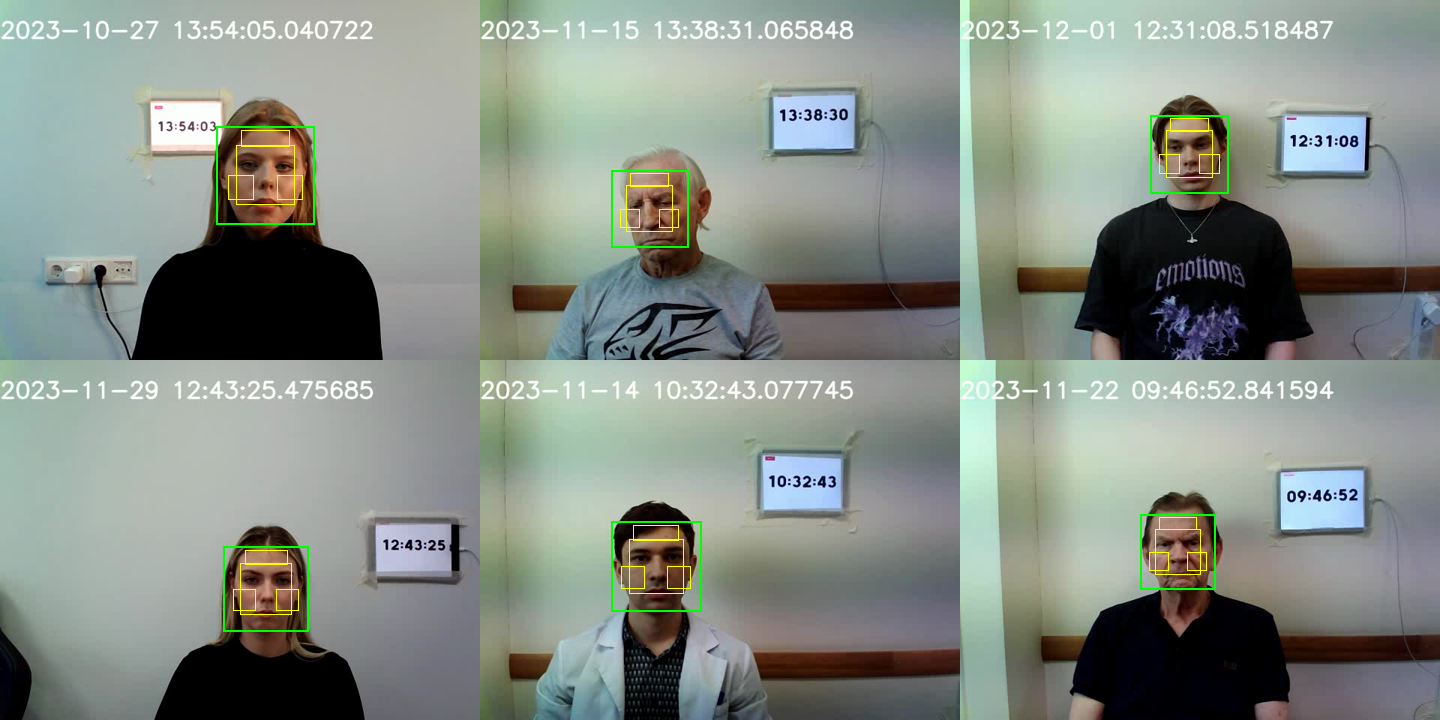

In [28]:
patch = '''

# ---- PATCH: per-video face detection (OpenCV 4.x Haar). No silent fallback to the fixed box. ----
def _detector():
    try:
        import cv2
    except Exception:
        return None, None
    if not hasattr(cv2, "CascadeClassifier"): return None, None
    p = Path(__file__).resolve().parent / "haarcascade_frontalface_default.xml"
    if not p.exists(): return None, None
    c = cv2.CascadeClassifier(str(p))
    return (cv2, c) if not c.empty() else (None, None)

def detect_box(frames, every=10):
    cv2, c = _detector()
    if c is None: return None
    boxes = []
    for i, fr in enumerate(frames):
        if i % every: continue
        f = c.detectMultiScale(cv2.cvtColor(fr, cv2.COLOR_RGB2GRAY), 1.1, 5, minSize=(40, 40))
        if len(f): boxes.append(max(f, key=lambda r: r[2] * r[3]))
    return np.median(np.array(boxes, float), 0) if len(boxes) >= 3 else None

def overlay(frame, box=None):
    out = np.array(frame, np.uint8, copy=True); H, W = out.shape[:2]
    x, y, w, h = box if box is not None else box_for(H, W)
    def rect(xa, ya, xb, yb, col, t):
        xa, xb = int(max(0, xa)), int(min(W, xb)); ya, yb = int(max(0, ya)), int(min(H, yb))
        out[ya:ya + t, xa:xb] = col; out[yb - t:yb, xa:xb] = col
        out[ya:yb, xa:xa + t] = col; out[ya:yb, xb - t:xb] = col
    rect(x, y, x + w, y + h, (0, 255, 0), 2)
    for x0, x1, y0, y1 in ROIS: rect(x + x0 * w, y + y0 * h, x + x1 * w, y + y1 * h, (255, 255, 0), 1)
    return out

def extract_signals(video_path, max_s=None, n_detect=150):
    frames, fps = iter_frames(video_path, max_s=max_s)
    buf = []
    for fr in frames:
        buf.append(fr)
        if len(buf) >= n_detect: break
    box = detect_box(buf)
    if box is None: raise RuntimeError("no face found")
    def feat(fr):
        x, y, w, h = box; row = []
        for x0, x1, y0, y1 in ROIS:
            ya, yb = int(y + y0 * h), max(int(y + y1 * h), int(y + y0 * h) + 1)
            xa, xb = int(x + x0 * w), max(int(x + x1 * w), int(x + x0 * w) + 1)
            row.extend(fr[max(ya, 0):yb, max(xa, 0):xb].reshape(-1, 3).mean(0))
        return row
    feats = [feat(fr) for fr in buf] + [feat(fr) for fr in frames]
    return np.array(feats, float), fps
'''
open("pulsepal_core.py", "a").write(patch)

import importlib, pulsepal_core; importlib.reload(pulsepal_core)
from pulsepal_core import *
tiles = []
for pid in sub.patient_id.unique()[:6]:
    r = sub[sub.patient_id == pid].iloc[0]
    frames, _ = iter_frames(RAW / r.video)
    buf = [next(frames) for _ in range(60)]; frames.close()
    b = detect_box(buf); print(pid, "box:", None if b is None else b.round(0))
    tiles.append(overlay(buf[0], b))
grid = np.concatenate([np.concatenate(tiles[:3], 1), np.concatenate(tiles[3:6], 1)], 0)
save_png(grid, "box_check_grid.png")
from IPython.display import Image, display; display(Image(filename="box_check_grid.png"))

In [30]:
!rm -f data/signals/*.npz

In [1]:
PILOT = 10                # None = process everything

from joblib import Parallel, delayed
from tqdm.auto import tqdm

def process_one(r):
    out = SIG / f"{r.patient_id}_{r.step}.npz"
    if out.exists(): return "cached"
    try:
        sig, fps = extract_signals(RAW / r.video, max_s=MAX_SECONDS)
        if len(sig) < 20 * FPS: return "too_short"
        ppg = load_ppg(RAW / r.ppg_sync, PPG_COL)[:len(sig)]          # about 1 ppg row per video frame
        if len(ppg) < 0.9 * len(sig): return "ppg_short"
        n30 = int(round(len(sig) * FPS / fps))
        s30, p30 = resample(sig, n30), resample(ppg, n30)[:, 0]
        s30, p30, lag, corr = align(s30, p30)
        if abs(corr) < 0.15: return "bad_sync"
        np.savez_compressed(out, sig=s30.astype(np.float32), ppg=p30.astype(np.float32), lag=lag, corr=corr)
        return "ok"
    except Exception as e:
        return f"error: {type(e).__name__}: {str(e)[:80]}"

rows = list(sub.itertuples()); rows = rows[:PILOT] if PILOT else rows
res = Parallel(n_jobs=N_JOBS, prefer="threads")(delayed(process_one)(r) for r in tqdm(rows))
print(Counter(res))
info = [np.load(f) for f in sorted(SIG.glob("*.npz"))]
if info:
    print("lag frames (5/50/95%):", np.percentile([int(i["lag"]) for i in info], [5, 50, 95]),
          "| |corr| (5/50/95%):", np.percentile([abs(float(i["corr"])) for i in info], [5, 50, 95]).round(2))

NameError: name 'sub' is not defined

In [2]:
from pathlib import Path
import os, getpass, numpy as np, pandas as pd
from collections import Counter
from pulsepal_core import *

BASE = Path.cwd(); RAW = BASE/"data"/"mcd_rppg"; SIG = BASE/"data"/"signals"; MODELS = BASE/"models"
for p in (RAW, SIG, MODELS): p.mkdir(parents=True, exist_ok=True)

REPO = "kyegorov/mcd_rppg"
BUDGET_GB, MAX_PATIENTS, SEED = 5, 200, 42
PPG_COL = 0               # ppg_sync column 0 = PPG waveform (verified from the real file)
N_JOBS = 2                # parallel video workers; check os.cpu_count()
MAX_SECONDS = 60          # use the first 60 s of each video (enough windows, much faster)

if not os.environ.get("HF_TOKEN"):
    t = getpass.getpass("NEW HF token (Enter to skip): ")
    if t: os.environ["HF_TOKEN"] = t

if (RAW/"db.csv").exists() and (BASE/"data"/"subset.csv").exists():      # reload after a kernel restart
    db = pd.read_csv(RAW/"db.csv"); sub = pd.read_csv(BASE/"data"/"subset.csv"); print("reloaded db and sub:", len(sub), "videos")

NEW HF token (Enter to skip):  ········


reloaded db and sub: 90 videos


In [4]:
PILOT = None                # None = process everything

from joblib import Parallel, delayed
from tqdm.auto import tqdm

def process_one(r):
    out = SIG / f"{r.patient_id}_{r.step}.npz"
    if out.exists(): return "cached"
    try:
        sig, fps = extract_signals(RAW / r.video, max_s=MAX_SECONDS)
        if len(sig) < 20 * FPS: return "too_short"
        ppg = load_ppg(RAW / r.ppg_sync, PPG_COL)[:len(sig)]          # about 1 ppg row per video frame
        if len(ppg) < 0.9 * len(sig): return "ppg_short"
        n30 = int(round(len(sig) * FPS / fps))
        s30, p30 = resample(sig, n30), resample(ppg, n30)[:, 0]
        s30, p30, lag, corr = align(s30, p30)
        if abs(corr) < 0.15: return "bad_sync"
        np.savez_compressed(out, sig=s30.astype(np.float32), ppg=p30.astype(np.float32), lag=lag, corr=corr)
        return "ok"
    except Exception as e:
        return f"error: {type(e).__name__}: {str(e)[:80]}"

rows = list(sub.itertuples()); rows = rows[:PILOT] if PILOT else rows
res = Parallel(n_jobs=N_JOBS, prefer="threads")(delayed(process_one)(r) for r in tqdm(rows))
print(Counter(res))
info = [np.load(f) for f in sorted(SIG.glob("*.npz"))]
if info:
    print("lag frames (5/50/95%):", np.percentile([int(i["lag"]) for i in info], [5, 50, 95]),
          "| |corr| (5/50/95%):", np.percentile([abs(float(i["corr"])) for i in info], [5, 50, 95]).round(2))

  0%|          | 0/90 [00:00<?, ?it/s]

Counter({'ok': 80, 'cached': 8, 'bad_sync': 2})
lag frames (5/50/95%): [-15.65   2.     8.95] | |corr| (5/50/95%): [0.35 0.63 0.9 ]


In [5]:
import torch
torch.set_num_threads(os.cpu_count()); torch.manual_seed(SEED)
X, Y, HR, HRP, PID, STEP = [], [], [], [], [], []
for fp in sorted(SIG.glob("*.npz")):
    pid, step = fp.stem.split("_"); d = np.load(fp)
    sg = d["sig"].astype(float); x = preprocess(sg); y = bandpass(d["ppg"].astype(float), FPS, 0.6, 3.5)
    pos = bandpass(pos_signal(sg.reshape(-1, 4, 3).mean(1), FPS), FPS, 0.6, 3.5)
    for s in range(0, len(x) - L + 1, STRIDE_S * FPS):
        xw, yw = x[s:s+L], y[s:s+L]
        X.append(((xw - xw.mean(0)) / (xw.std(0) + 1e-8)).T.astype(np.float32))
        Y.append(((yw - yw.mean()) / (yw.std() + 1e-8)).astype(np.float32))
        HR.append(hr_snr(yw)[0]); HRP.append(hr_snr(pos[s:s+L])[0]); PID.append(int(pid)); STEP.append(step)
X, Y, HR, HRP, PID, STEP = map(np.array, (X, Y, HR, HRP, PID, STEP))

pids = np.array(sorted(set(PID.tolist()))); np.random.default_rng(SEED).shuffle(pids); n = len(pids)
sets = [set(pids[a:b].tolist()) for a, b in ((0, int(.7*n)), (int(.7*n), int(.85*n)), (int(.85*n), n))]
mtr, mva, mte = [np.array([p in S for p in PID]) for S in sets]
print(f"{n} patients | windows train {mtr.sum()} / val {mva.sum()} / test {mte.sum()}")

Xtr, Ytr = torch.tensor(X[mtr]), torch.tensor(Y[mtr])
model = PulseNet(); opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=1e-4)
best, state = 1e9, None
for ep in range(15):
    model.train(); perm = torch.randperm(len(Xtr)); tl = 0.0
    for i in range(0, len(perm), 64):
        b = perm[i:i+64]; xb = Xtr[b] + 0.05 * torch.randn_like(Xtr[b])
        loss = pearson_loss(model(xb), Ytr[b]); opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(b)
    mae = np.abs(np.array([hr_snr(w)[0] for w in predict(model, X[mva])]) - HR[mva]).mean()
    print(f"epoch {ep+1:02d} | train loss {tl/len(Xtr):.3f} | val HR MAE {mae:.2f} bpm")
    if mae < best: best, state = mae, {k: v.clone() for k, v in model.state_dict().items()}
model.load_state_dict(state)
torch.save({"state": model.state_dict(), "in_ch": 12, "hid": 64}, MODELS / "pulsenet.pt")
print("saved best model, val MAE", round(best, 2))

44 patients | windows train 601 / val 140 / test 140
epoch 01 | train loss 0.426 | val HR MAE 0.94 bpm
epoch 02 | train loss 0.251 | val HR MAE 0.82 bpm
epoch 03 | train loss 0.227 | val HR MAE 0.84 bpm
epoch 04 | train loss 0.210 | val HR MAE 0.79 bpm
epoch 05 | train loss 0.195 | val HR MAE 0.81 bpm
epoch 06 | train loss 0.179 | val HR MAE 0.76 bpm
epoch 07 | train loss 0.166 | val HR MAE 0.89 bpm
epoch 08 | train loss 0.150 | val HR MAE 0.83 bpm
epoch 09 | train loss 0.136 | val HR MAE 0.88 bpm
epoch 10 | train loss 0.125 | val HR MAE 1.13 bpm
epoch 11 | train loss 0.114 | val HR MAE 1.20 bpm
epoch 12 | train loss 0.106 | val HR MAE 0.98 bpm
epoch 13 | train loss 0.096 | val HR MAE 1.21 bpm
epoch 14 | train loss 0.091 | val HR MAE 0.90 bpm
epoch 15 | train loss 0.082 | val HR MAE 0.99 bpm
saved best model, val MAE 0.76


In [6]:
W = predict(model, X[mte]); r_ = np.array([hr_snr(w) for w in W]); hr_m, snr_m = r_[:, 0], r_[:, 1]
def mt(ref, est):
    e = est - ref
    return {k: round(float(v), 2) for k, v in dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e**2).mean()),
            r=np.corrcoef(ref, est)[0, 1], within5=100*(np.abs(e) <= 5).mean()).items()}
print("POS  :", mt(HR[mte], HRP[mte])); print("Model:", mt(HR[mte], hr_m))
for s in ("before", "after"):
    k = STEP[mte] == s; print(f"{s:<6} n={k.sum():<5} POS MAE {mt(HR[mte][k], HRP[mte][k])['MAE']} | model MAE {mt(HR[mte][k], hr_m[k])['MAE']}")
for thr in (-6, -3, 0, 3):
    k = snr_m >= thr
    if k.sum() > 10: print(f"SNR >= {thr:>2} dB: keeps {100*k.mean():.0f}% of windows, MAE {np.abs(hr_m[k]-HR[mte][k]).mean():.2f}")

lab = db.drop_duplicates(["patient_id", "step"]).set_index(["patient_id", "step"])
d = pd.DataFrame(dict(pid=PID[mte], step=STEP[mte], ref=HR[mte], model=hr_m)).groupby(["pid", "step"]).median().reset_index()
pairs = []
for r in d.itertuples():
    q = lab.loc[(r.pid, r.step)]
    kw = dict(rr=q.respiratory, spo2=q.saturation, sbp=q.upper_ap, temp=q.temperature, age=q.age)
    pairs.append((assess(hr=r.ref, **kw)["light"], assess(hr=r.model, **kw)["light"]))
pr = pd.DataFrame(pairs, columns=["reference_HR", "model_HR"])
print(f"traffic-light agreement: {(pr.reference_HR == pr.model_HR).mean()*100:.1f}% of {len(pr)} recordings")
print(pd.crosstab(pr.reference_HR, pr.model_HR))

POS  : {'MAE': 9.08, 'RMSE': 19.03, 'r': 0.4, 'within5': 72.14}
Model: {'MAE': 4.14, 'RMSE': 10.78, 'r': 0.7, 'within5': 87.14}
before n=70    POS MAE 8.35 | model MAE 3.23
after  n=70    POS MAE 9.82 | model MAE 5.05
SNR >= -6 dB: keeps 100% of windows, MAE 4.14
SNR >= -3 dB: keeps 96% of windows, MAE 3.80
SNR >=  0 dB: keeps 78% of windows, MAE 2.08
SNR >=  3 dB: keeps 49% of windows, MAE 1.35
traffic-light agreement: 100.0% of 14 recordings
model_HR      GREEN  YELLOW
reference_HR               
GREEN             3       0
YELLOW            0      11


In [7]:
   s = open("app.py").read()
   s = s.replace("left:31.25%;top:25%;width:37.5%;height:50%", "left:36.875%;top:32.5%;width:26.25%;height:35%")
   s = s.replace("const S=0.5*c.height", "const S=0.35*c.height")
   open("app.py", "w").write(s); print("guide resized")

FileNotFoundError: [Errno 2] No such file or directory: 'app.py'

In [8]:
f = sorted(SIG.glob("*.npz"))[0]; d = np.load(f)
est = estimate_hr(model, d["sig"].astype(float))
ref = np.median([hr_snr(d["ppg"][s:s+L].astype(float))[0] for s in range(0, len(d["ppg"]) - L, 150)])
print(f.name, est, "| reference HR:", round(ref, 1))

1149_after.npz {'hr': 66.796875, 'snr_db': -0.0885152023086725, 'spread': 3.0670950872369276, 'n_windows': 25} | reference HR: 67.0


In [9]:
%%writefile app.py
import os, numpy as np, torch
from flask import Flask, request, jsonify, Response
from pulsepal_core import *

torch.set_num_threads(2)
app = Flask(__name__)
ck = torch.load("models/pulsenet.pt", map_location="cpu")
model = PulseNet(ck["in_ch"], ck["hid"]); model.load_state_dict(ck["state"]); model.eval()
SNR_GATE, MIN_SECONDS = 0.0, 20          # set SNR_GATE from Step 10

PAGE = r"""<!doctype html><html><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>PulsePal AI</title>
<style>
 body{font-family:system-ui,sans-serif;max-width:760px;margin:0 auto;padding:12px}
 #wrap{position:relative;display:block;width:100%;max-width:480px}
 video{width:100%;background:#000;transform:scaleX(-1)}
 #guide{position:absolute;left:31.25%;top:25%;width:37.5%;height:50%;border:3px solid #22c55e;pointer-events:none}
 fieldset{margin:10px 0} label{display:inline-block;margin:4px 10px 4px 0} input{width:80px}
 button{padding:10px 16px;font-size:16px} .badge{color:#fff;font-size:22px;font-weight:700;padding:12px;border-radius:8px;margin:12px 0}
 table{border-collapse:collapse} td,th{border:1px solid #ccc;padding:4px 10px} .small{color:#555;font-size:13px}
</style></head><body>
<h2>PulsePal AI</h2>
<p class="small">Screening aid, not a diagnosis. A nurse makes the decision. Adults (18+) only.</p>
<div id="wrap"><video id="v" autoplay playsinline muted></video><div id="guide"></div></div>
<canvas id="c" width="320" height="240" hidden></canvas>
<fieldset><legend>Details (typed in)</legend>
 <label>Age <input id="age" type="number" placeholder="yrs"></label>
 <label>Resp. rate <input id="rr" type="number" placeholder="/min"></label>
 <label>SpO2 <input id="spo2" type="number" placeholder="%"></label>
 <label>Systolic BP <input id="sbp" type="number" placeholder="mmHg"></label>
 <label>Temp <input id="temp" type="number" step="0.1" placeholder="C"></label>
 <label>Heart rate (optional) <input id="hr_manual" type="number" placeholder="bpm"></label>
</fieldset>
<button id="start" disabled>Start 30 s scan</button> <span id="status">Starting camera...</span>
<div id="report"></div>
<script>
const DUR=30, ROIS=[[.25,.75,.05,.22],[.12,.38,.50,.75],[.62,.88,.50,.75],[.20,.80,.20,.80]];
const v=document.getElementById('v'), c=document.getElementById('c'), ctx=c.getContext('2d',{willReadFrequently:true});
const st=document.getElementById('status'), rep=document.getElementById('report'), btn=document.getElementById('start');
let rec=null;
(async()=>{ try{
  const s=await navigator.mediaDevices.getUserMedia({video:{width:640,height:480,frameRate:30,facingMode:'user'},audio:false});
  v.srcObject=s; await v.play(); st.textContent='Camera ready. Fit your face in the green square, face the light.'; btn.disabled=false;
 }catch(e){ st.textContent='Camera not available: '+e.message+' (page must be HTTPS or localhost)'; } })();
function sample(){
  ctx.drawImage(v,0,0,c.width,c.height);
  const S=0.5*c.height, X0=(c.width-S)/2, Y0=(c.height-S)/2, row=[];
  for(const [x0,x1,y0,y1] of ROIS){
    const x=Math.round(X0+x0*S), y=Math.round(Y0+y0*S), w=Math.max(1,Math.round((x1-x0)*S)), h=Math.max(1,Math.round((y1-y0)*S));
    const d=ctx.getImageData(x,y,w,h).data; let r=0,g=0,b=0; const n=d.length/4;
    for(let i=0;i<d.length;i+=4){r+=d[i];g+=d[i+1];b+=d[i+2]}
    row.push(r/n,g/n,b/n);
  } return row;
}
function schedule(){ if('requestVideoFrameCallback' in v) v.requestVideoFrameCallback(loop); else requestAnimationFrame(loop); }
function loop(){ if(!rec) return; const t=performance.now()-rec.t0; rec.t.push(t); rec.rgb.push(sample());
  st.textContent='Recording '+Math.round(t/1000)+' / '+DUR+' s - stay still'; if(t>=DUR*1000) finish(); else schedule(); }
btn.onclick=()=>{ rep.innerHTML=''; rec={t0:performance.now(),t:[],rgb:[]}; btn.disabled=true; schedule(); };
async function finish(){
  const r=rec; rec=null; st.textContent='Analysing...'; const val=id=>document.getElementById(id).value;
  const body={t:r.t,rgb:r.rgb,age:val('age'),rr:val('rr'),spo2:val('spo2'),sbp:val('sbp'),temp:val('temp'),hr_manual:val('hr_manual')};
  try{ const res=await fetch('/analyze',{method:'POST',headers:{'Content-Type':'application/json'},body:JSON.stringify(body)});
       const j=await res.json(); if(!res.ok){ st.textContent=j.error||'Error'; } else { st.textContent='Done'; show(j); }
  }catch(e){ st.textContent='Server error: '+e.message; }
  btn.disabled=false;
}
function show(j){
  const A=j.assessment, col={RED:'#dc2626',YELLOW:'#d97706',GREEN:'#16a34a'}[A.light]||'#6b7280';
  const label=A.light==='GREEN'?'GREEN - no urgent flags':A.light;
  let rows=''; for(const [k,[val,sc]] of Object.entries(A.items||{})) rows+=`<tr><td>${k}</td><td>${val}</td><td>${sc}</td></tr>`;
  rep.innerHTML=`<div class="badge" style="background:${col}">${label}</div>
   <p><b>Heart rate:</b> ${j.hr_used?Math.round(j.hr_used)+' bpm ('+j.hr_source+')':'not available ('+j.hr_source+')'}
      <span class="small"> | camera signal quality ${j.camera.snr_db.toFixed(1)} dB</span></p>
   ${A.note?'<p>'+A.note+'</p>':''}
   ${rows?'<table><tr><th>Vital</th><th>Value</th><th>Score</th></tr>'+rows+'</table><p>Partial NEWS2 total: '+A.total+'</p>':''}
   ${(A.flags||[]).map(f=>'<p>&#9888; '+f+'</p>').join('')}
   ${(j.warnings||[]).map(f=>'<p class="small">&#9432; '+f+'</p>').join('')}
   <p class="small">Respiratory rate, SpO2, BP and temperature were typed in, not measured by the camera. Screening aid only; clinical judgement applies.</p>
   <button onclick="window.print()">Print / save as PDF</button>`;
}
</script></body></html>"""

@app.get("/")
def index(): return Response(PAGE, mimetype="text/html")

def num(d, k):
    v = d.get(k)
    try: return None if v in (None, "") else float(v)
    except (TypeError, ValueError): return None

@app.post("/analyze")
def analyze():
    d = request.get_json(force=True, silent=True) or {}
    try: t = np.asarray(d["t"], float) / 1000.0; rgb = np.asarray(d["rgb"], float)
    except Exception: return jsonify(error="Bad data"), 400
    if rgb.ndim != 2 or rgb.shape[1] != 12 or len(t) != len(rgb) or not np.isfinite(rgb).all():
        return jsonify(error="Bad signal shape"), 400
    if len(t) < 60 or t[-1] - t[0] < MIN_SECONDS:
        return jsonify(error="Recording too short (need 20 s or more)"), 400
    grid = np.arange(t[0], t[-1], 1.0 / FPS)
    sig = np.stack([np.interp(grid, t, rgb[:, c]) for c in range(12)], 1)
    warn, m = [], float(rgb.mean())
    if m < 40: warn.append("Too dark - add light in front of your face")
    if m > 235: warn.append("Too bright / overexposed")
    est = estimate_hr(model, sig)
    if est is None: return jsonify(error="Not enough signal"), 400
    ok = est["snr_db"] >= SNR_GATE and est["spread"] <= 10
    if not ok: warn.append("Pulse signal is weak - stay still, face the light, retake")
    hm = num(d, "hr_manual")
    hr_used, src = (hm, "typed in") if hm else ((est["hr"], "camera") if ok else (None, "unreliable"))
    A = assess(hr=hr_used, rr=num(d, "rr"), spo2=num(d, "spo2"), sbp=num(d, "sbp"), temp=num(d, "temp"), age=num(d, "age"))
    return jsonify(camera=est, quality_ok=bool(ok), warnings=warn, hr_used=hr_used, hr_source=src, assessment=A)

if __name__ == "__main__":
    ctx = ("cert.pem", "key.pem") if os.path.exists("cert.pem") else None
    app.run(host="0.0.0.0", port=5000, ssl_context=ctx)

Writing app.py


In [10]:
f = sorted(SIG.glob("*.npz"))[0]; d = np.load(f)
est = estimate_hr(model, d["sig"].astype(float))
ref = np.median([hr_snr(d["ppg"][s:s+L].astype(float))[0] for s in range(0, len(d["ppg"]) - L, 150)])
print(f.name, est, "| reference HR:", round(ref, 1))

1149_after.npz {'hr': 66.796875, 'snr_db': -0.0885152023086725, 'spread': 3.0670950872369276, 'n_windows': 25} | reference HR: 67.0


In [11]:
s = open("app.py").read()
s = s.replace('ck = torch.load("models/pulsenet.pt", map_location="cpu")\n', 'z = np.load("models/pulsenet_portable.npz")\n')
s = s.replace('model = PulseNet(ck["in_ch"], ck["hid"]); model.load_state_dict(ck["state"]); model.eval()',
              'model = PulseNet(12, 64); model.load_state_dict({k: torch.from_numpy(np.ascontiguousarray(z[k])) for k in z.files}); model.eval()')
open("app.py", "w").write(s)

7405

In [12]:
f = sorted(SIG.glob("*.npz"))[0]; d = np.load(f)
est = estimate_hr(model, d["sig"].astype(float))
ref = np.median([hr_snr(d["ppg"][s:s+L].astype(float))[0] for s in range(0, len(d["ppg"]) - L, 150)])
print(f.name, est, "| reference HR:", round(ref, 1))

1149_after.npz {'hr': 66.796875, 'snr_db': -0.0885152023086725, 'spread': 3.0670950872369276, 'n_windows': 25} | reference HR: 67.0


In [13]:
import numpy as np, torch
ck = torch.load(MODELS / "pulsenet.pt", map_location="cpu")
np.savez(MODELS / "pulsenet_portable.npz",
         **{k: v.numpy().astype("<f4" if v.dtype.is_floating_point else "<i8") for k, v in ck["state"].items()})
print("saved:", (MODELS / "pulsenet_portable.npz").exists())

saved: True


In [14]:
s = open("app.py").read()
s = s.replace("fieldset{", ".roi{position:absolute;border:1.5px solid #facc15;pointer-events:none} fieldset{", 1)
s = s.replace("let rec=null;", """let rec=null;
(function(){ const g=document.getElementById('guide');
  for(const [x0,x1,y0,y1] of ROIS){ const d=document.createElement('div'); d.className='roi';
    d.style.cssText=`left:${x0*100}%;top:${y0*100}%;width:${(x1-x0)*100}%;height:${(y1-y0)*100}%`; g.appendChild(d); } })();""", 1)
open("app.py", "w").write(s); print("yellow boxes added")

yellow boxes added
